<a href="https://colab.research.google.com/github/dzakki08/Studi_Kasus_Introduction_to_Machine_Learning.ipynb/blob/main/Studi_Kasus_Final_Introduction_ML_Klasifikasi_Email_Spam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STUDI KASUS LENGKAP: INTRODUCTION TO MACHINE LEARNING
# Klasifikasi Email Spam Menggunakan Machine Learning

**Nama:** Muhammad Farhan Dzakki  
**NPM:** G1A023041  
**Program Studi:** Informatika  
**Fakultas:** Teknik  
**Universitas:** Universitas Bengkulu  

---

## Ringkasan

Notebook ini menerapkan konsep dasar *Machine Learning* untuk mengklasifikasikan email sebagai spam atau bukan spam berdasarkan sejumlah karakteristik sederhana. Materi mencakup pengertian AI dan ML, jenis-jenis Machine Learning, pemahaman data, penentuan fitur dan target, pembagian data training dan testing, pelatihan Logistic Regression, evaluasi, serta prediksi data baru.

**Catatan:** dataset dibuat secara sintetis untuk pembelajaran dan bukan berasal dari email atau pengguna nyata. Hasil model hanya mendemonstrasikan alur kerja ML dan tidak boleh dianggap sebagai filter spam siap pakai.

## 1. Latar Belakang

Email masih dapat digunakan untuk menyebarkan promosi yang tidak diinginkan, penipuan, atau pesan berbahaya. Salah satu pendekatan untuk membantu memilah email adalah klasifikasi otomatis berdasarkan karakteristik pesan. Machine Learning dapat mempelajari pola dari contoh email yang sudah diberi label, lalu menggunakan pola tersebut untuk memprediksi label pada email baru.

Pada studi kasus ini, model mempelajari fitur numerik simulasi seperti jumlah tautan, jumlah kata yang dianggap mencurigakan, penggunaan huruf kapital, panjang pesan, dan keberadaan lampiran.

## 2. Rumusan Masalah

1. Bagaimana karakteristik dataset simulasi email spam?
2. Bagaimana menentukan fitur dan target untuk masalah klasifikasi?
3. Bagaimana melatih model Machine Learning untuk membedakan spam dan bukan spam?
4. Bagaimana mengevaluasi model pada data yang tidak digunakan saat pelatihan?

## 3. Tujuan

- Memahami alur dasar Machine Learning.
- Mengenali fitur dan target dalam masalah klasifikasi.
- Melakukan pemeriksaan dan eksplorasi dataset.
- Membagi dataset menjadi data training dan testing.
- Melatih model Logistic Regression.
- Mengevaluasi hasil menggunakan Accuracy, Precision, Recall, F1-score, dan confusion matrix.
- Mencoba prediksi pada contoh email baru.

## 4. Konsep Utama

- **Artificial Intelligence (AI):** bidang yang mempelajari sistem untuk melakukan tugas yang biasanya membutuhkan kecerdasan manusia.
- **Machine Learning (ML):** pendekatan yang memungkinkan model mempelajari pola dari data.
- **Deep Learning:** bagian dari ML yang menggunakan jaringan saraf berlapis.
- **Fitur:** variabel masukan yang digunakan model untuk membuat prediksi.
- **Target/label:** hasil yang ingin diprediksi.
- **Klasifikasi:** tugas memprediksi kategori, misalnya spam atau bukan spam.

## 5. Jenis-Jenis Machine Learning

| Jenis | Karakteristik | Contoh |
|---|---|---|
| Supervised Learning | Data latihan memiliki label | Klasifikasi spam, prediksi kelulusan |
| Unsupervised Learning | Data tidak memiliki label target | Pengelompokan pelanggan |
| Reinforcement Learning | Agen belajar melalui tindakan dan umpan balik | Agen yang belajar bermain permainan |

Studi kasus ini termasuk **Supervised Learning** karena setiap contoh pada dataset memiliki label `spam`.

## 6. Studi Kasus dan Definisi Variabel

Dataset simulasi memiliki variabel berikut:

- `jumlah_tautan`: jumlah tautan di dalam email.
- `kata_mencurigakan`: jumlah kata/ungkapan yang dianggap mencurigakan pada contoh simulasi.
- `rasio_huruf_kapital`: proporsi karakter huruf kapital (0–1).
- `panjang_pesan`: panjang pesan dalam jumlah karakter.
- `ada_lampiran`: 1 jika terdapat lampiran, 0 jika tidak.
- `spam`: target klasifikasi; 1 berarti spam dan 0 berarti bukan spam.

Variabel tersebut hanya contoh fitur yang disederhanakan. Sistem nyata biasanya memerlukan analisis isi pesan, konteks, reputasi pengirim, dan mekanisme keamanan yang lebih lengkap.

## 7. Menyiapkan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, confusion_matrix
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
print("Library berhasil diimpor.")

Library berhasil diimpor.


## 8. Membuat Dataset Simulasi

In [2]:
rng = np.random.default_rng(2026)
n = 700

jumlah_tautan = rng.poisson(1.2, n).clip(0, 10)
kata_mencurigakan = rng.poisson(1.0, n).clip(0, 8)
rasio_huruf_kapital = rng.beta(1.5, 8, n).clip(0, 1)
panjang_pesan = rng.integers(40, 2500, n)
ada_lampiran = rng.binomial(1, 0.25, n)

# Label dibentuk dari skor simulasi; bukan data email sungguhan.
logit = (
    -2.0
    + 0.42 * jumlah_tautan
    + 0.75 * kata_mencurigakan
    + 3.0 * rasio_huruf_kapital
    + 0.35 * ada_lampiran
    - 0.00025 * panjang_pesan
)
prob_spam = 1 / (1 + np.exp(-logit))
spam = rng.binomial(1, prob_spam)

df = pd.DataFrame({
    "jumlah_tautan": jumlah_tautan,
    "kata_mencurigakan": kata_mencurigakan,
    "rasio_huruf_kapital": rasio_huruf_kapital.round(3),
    "panjang_pesan": panjang_pesan,
    "ada_lampiran": ada_lampiran,
    "spam": spam
})

print("Lima data pertama:")
display(df.head())
print("Ukuran dataset:", df.shape)

Lima data pertama:


,jumlah_tautan,kata_mencurigakan,rasio_huruf_kapital,panjang_pesan,ada_lampiran,spam
0,0,3,0.028,2161,0,0
1,1,0,0.014,2353,1,0
2,1,0,0.076,662,0,1
3,2,1,0.258,2441,1,0
4,1,0,0.519,128,0,1


Ukuran dataset: (700, 6)


## 9. Memahami Data (Data Understanding)

Pemeriksaan awal meliputi ukuran data, tipe data, nilai kosong, duplikasi, statistik ringkas, dan distribusi target. Tahap ini membantu memahami data sebelum model dilatih.

In [3]:
print("Ukuran dataset:", df.shape)
print("\\nTipe data:")
print(df.dtypes)
print("\\nNilai kosong per kolom:")
display(df.isna().sum().to_frame("jumlah_missing"))
print("Jumlah baris duplikat:", df.duplicated().sum())
print("\\nStatistik ringkas:")
display(df.describe().round(3))
print("\\nDistribusi target (0 = bukan spam, 1 = spam):")
display(df["spam"].value_counts().sort_index().rename(index={0:"Bukan spam (0)",1:"Spam (1)"}).to_frame("jumlah"))

Ukuran dataset: (700, 6)
\nTipe data:
jumlah_tautan            int64
kata_mencurigakan        int64
rasio_huruf_kapital    float64
panjang_pesan            int64
ada_lampiran             int64
spam                     int64
dtype: object
\nNilai kosong per kolom:


,jumlah_missing
jumlah_tautan,0
kata_mencurigakan,0
rasio_huruf_kapital,0
panjang_pesan,0
ada_lampiran,0
spam,0


Jumlah baris duplikat: 0
\nStatistik ringkas:


,jumlah_tautan,kata_mencurigakan,rasio_huruf_kapital,panjang_pesan,ada_lampiran,spam
count,700.000,700.000,700.000,700.000,700.000,700.000
mean,1.276,0.947,0.153,1301.291,0.227,0.379
std,1.141,0.978,0.110,718.916,0.419,0.485
min,0.000,0.000,0.002,41.000,0.000,0.000
25%,0.000,0.000,0.072,645.750,0.000,0.000
50%,1.000,1.000,0.130,1353.500,0.000,0.000
75%,2.000,1.000,0.216,1913.250,0.000,1.000
max,9.000,5.000,0.655,2499.000,1.000,1.000


\nDistribusi target (0 = bukan spam, 1 = spam):


,jumlah
spam,
Bukan spam (0),435
Spam (1),265


### Visualisasi distribusi target

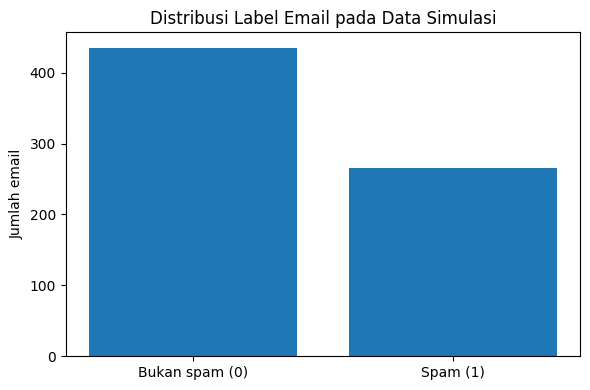

In [4]:
counts = df["spam"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["Bukan spam (0)", "Spam (1)"], counts.values)
plt.title("Distribusi Label Email pada Data Simulasi")
plt.ylabel("Jumlah email")
plt.tight_layout()
plt.show()

**Interpretasi:** perhatikan jumlah contoh pada masing-masing kelas. Jika kelas tidak seimbang, accuracy saja dapat memberikan gambaran yang kurang lengkap. Untuk penggunaan nyata, distribusi label harus diperiksa menggunakan dataset yang representatif.

### Visualisasi fitur berdasarkan label

<Figure size 700x400 with 0 Axes>

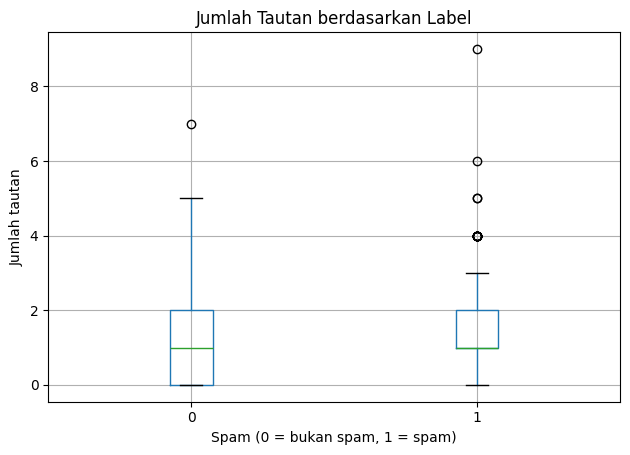

<Figure size 700x400 with 0 Axes>

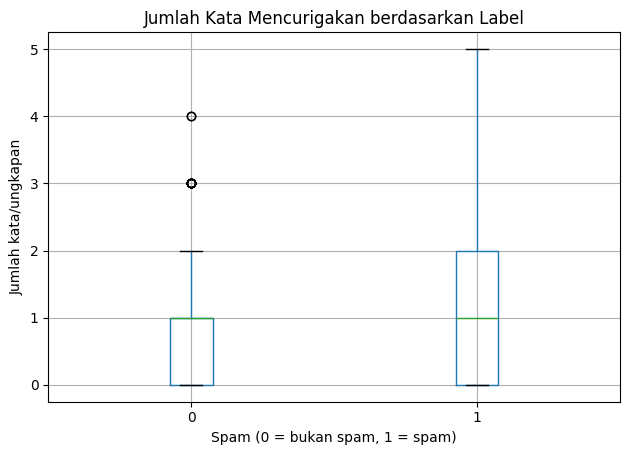

In [5]:
plt.figure(figsize=(7, 4))
df.boxplot(column="jumlah_tautan", by="spam")
plt.title("Jumlah Tautan berdasarkan Label")
plt.suptitle("")
plt.xlabel("Spam (0 = bukan spam, 1 = spam)")
plt.ylabel("Jumlah tautan")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
df.boxplot(column="kata_mencurigakan", by="spam")
plt.title("Jumlah Kata Mencurigakan berdasarkan Label")
plt.suptitle("")
plt.xlabel("Spam (0 = bukan spam, 1 = spam)")
plt.ylabel("Jumlah kata/ungkapan")
plt.tight_layout()
plt.show()

## 10. Menyiapkan Fitur dan Target

Fitur merupakan masukan model, sedangkan target adalah kategori yang ingin diprediksi. Kolom `spam` tidak dimasukkan ke dalam fitur karena akan menyebabkan kebocoran target.

In [6]:
features = [
    "jumlah_tautan",
    "kata_mencurigakan",
    "rasio_huruf_kapital",
    "panjang_pesan",
    "ada_lampiran"
]
X = df[features]
y = df["spam"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))
print("Proporsi spam pada training:", round(y_train.mean() * 100, 2), "%")
print("Proporsi spam pada testing:", round(y_test.mean() * 100, 2), "%")

Jumlah data training: 560
Jumlah data testing: 140
Proporsi spam pada training: 37.86 %
Proporsi spam pada testing: 37.86 %


## 11. Melatih Model

Model yang digunakan adalah **Logistic Regression**, algoritma klasifikasi yang memperkirakan probabilitas suatu observasi termasuk dalam kelas tertentu. `StandardScaler` digunakan untuk menstandarkan fitur numerik. Preprocessing ditempatkan dalam pipeline sehingga scaler hanya dipelajari dari data training.

In [7]:
model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

model.fit(X_train, y_train)
print("Pelatihan model selesai.")

Pelatihan model selesai.


## 12. Evaluasi Model

Evaluasi dilakukan pada data testing yang tidak digunakan saat pelatihan.

- **Accuracy:** proporsi seluruh prediksi yang benar.
- **Precision:** dari seluruh email yang diprediksi spam, proporsi yang benar-benar spam.
- **Recall:** dari seluruh email spam aktual, proporsi yang berhasil dikenali.
- **F1-score:** keseimbangan antara Precision dan Recall.

Pada sistem penyaringan email, kesalahan klasifikasi perlu diperhatikan: email penting yang salah masuk spam dapat merugikan pengguna, sementara spam yang lolos dapat mengganggu atau membahayakan.

In [8]:
y_pred = model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0)
}

print("Hasil evaluasi:")
display(pd.DataFrame([metrics]).round(3))

Hasil evaluasi:


,Accuracy,Precision,Recall,F1-score
0,0.714,0.741,0.377,0.5


### Classification report dan confusion matrix

              precision    recall  f1-score   support

  Bukan spam       0.71      0.92      0.80        87
        Spam       0.74      0.38      0.50        53

    accuracy                           0.71       140
   macro avg       0.72      0.65      0.65       140
weighted avg       0.72      0.71      0.69       140



,Prediksi bukan spam,Prediksi spam
Aktual bukan spam,80,7
Aktual spam,33,20


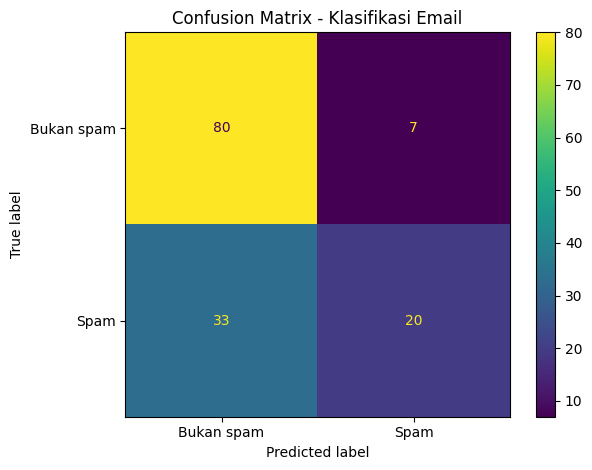

In [9]:
print(classification_report(
    y_test, y_pred,
    target_names=["Bukan spam", "Spam"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
display(pd.DataFrame(
    cm,
    index=["Aktual bukan spam", "Aktual spam"],
    columns=["Prediksi bukan spam", "Prediksi spam"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Bukan spam", "Spam"],
    values_format="d"
)
plt.title("Confusion Matrix - Klasifikasi Email")
plt.tight_layout()
plt.show()

**Cara membaca confusion matrix:**
- Prediksi benar untuk kelas bukan spam berarti email normal dikenali dengan benar.
- Prediksi benar untuk kelas spam berarti email spam dikenali dengan benar.
- Kesalahan dapat berupa email normal yang ditandai sebagai spam (*false positive*) atau spam yang diprediksi sebagai email normal (*false negative*).

## 13. Mencoba Prediksi Data Baru

Contoh berikut menggambarkan email hipotetis. Hasil prediksi berasal dari model yang dilatih pada data simulasi, bukan penilaian keamanan email sungguhan.

In [10]:
email_baru = pd.DataFrame([{
    "jumlah_tautan": 5,
    "kata_mencurigakan": 4,
    "rasio_huruf_kapital": 0.22,
    "panjang_pesan": 350,
    "ada_lampiran": 1
}])

prediksi = model.predict(email_baru)[0]
probabilitas = model.predict_proba(email_baru)[0]

print("Data email baru:")
display(email_baru)
print("Prediksi kelas:", "Spam" if prediksi == 1 else "Bukan spam")
print(f"Probabilitas bukan spam: {probabilitas[0]:.1%}")
print(f"Probabilitas spam: {probabilitas[1]:.1%}")

Data email baru:


,jumlah_tautan,kata_mencurigakan,rasio_huruf_kapital,panjang_pesan,ada_lampiran
0,5,4,0.22,350,1


Prediksi kelas: Spam
Probabilitas bukan spam: 4.5%
Probabilitas spam: 95.5%


## 14. Alur Kerja Machine Learning

1. **Pengumpulan data:** menyiapkan contoh email yang boleh digunakan dan diberi label dengan benar.
2. **Pembersihan data:** menangani data kosong, duplikasi, dan format yang tidak konsisten.
3. **Eksplorasi data:** memahami distribusi label dan karakteristik fitur.
4. **Pemilihan fitur dan target:** menentukan variabel masukan serta label yang diprediksi.
5. **Pembagian data:** memisahkan data training dan testing.
6. **Pelatihan model:** mempelajari pola dari data training.
7. **Evaluasi:** mengukur performa pada data testing.
8. **Penerapan dan pemantauan:** menguji model dalam lingkungan terbatas dan memantau kesalahan secara berkala.

## 15. Tantangan Machine Learning

- **Kualitas data:** label yang salah dapat membuat model mempelajari pola yang keliru.
- **Bias:** data latihan yang tidak representatif dapat menurunkan kinerja pada jenis email tertentu.
- **Overfitting:** model terlalu cocok dengan data training dan kurang mampu memprediksi data baru.
- **Perubahan pola:** teknik spam dapat berubah sehingga model perlu dievaluasi ulang.
- **False positive dan false negative:** kedua jenis kesalahan memiliki dampak yang berbeda bagi pengguna.

## 16. Etika dan Batasan Studi Kasus

1. Dataset dibuat secara sintetis dan tidak berisi email nyata.
2. Label dibentuk menggunakan rumus simulasi, sehingga model dapat mempelajari pola buatan tersebut.
3. Kata atau fitur tertentu tidak selalu membuktikan bahwa suatu email adalah spam.
4. Sistem nyata perlu menjaga privasi isi email dan membatasi akses terhadap data pengguna.
5. Hasil prediksi sebaiknya menjadi alat bantu penyaringan dan menyediakan mekanisme untuk memulihkan email yang salah ditandai.

## 17. Pertanyaan Diskusi

1. Mengapa kasus ini termasuk Supervised Learning?
2. Apa perbedaan fitur dan target dalam dataset?
3. Mengapa data perlu dibagi menjadi training dan testing?
4. Apa perbedaan Accuracy, Precision, Recall, dan F1-score?
5. Apa dampak false positive pada sistem penyaringan email?
6. Mengapa model yang diuji pada data simulasi belum dapat langsung digunakan untuk email nyata?

## 18. Pengembangan Lanjutan

- Bandingkan Logistic Regression dengan Decision Tree dan Random Forest.
- Tambahkan fitur teks menggunakan teknik pemrosesan bahasa alami, seperti TF-IDF.
- Gunakan cross-validation untuk memperkirakan performa yang lebih stabil.
- Periksa ketidakseimbangan kelas dan sesuaikan metrik evaluasi.
- Uji model pada data yang representatif, berizin, dan telah dianonimkan.

## 19. Kesimpulan

Studi kasus ini memperlihatkan alur dasar Machine Learning untuk klasifikasi email: memahami masalah, membuat dan memeriksa data, menentukan fitur dan target, membagi data, melatih model Logistic Regression, lalu mengevaluasi hasil menggunakan beberapa metrik. Model juga dicoba pada satu contoh email baru.

Karena dataset dan label bersifat sintetis, hasil yang diperoleh hanya menunjukkan proses pembelajaran dan tidak membuktikan bahwa model siap digunakan untuk menyaring email nyata. Pengembangan lebih lanjut memerlukan data yang representatif, perlindungan privasi, dan evaluasi kesalahan klasifikasi secara cermat.